In [70]:
import numpy as np
import matplotlib.pylab as plt
import healpy as hp
import sqlite3
%matplotlib inline
import pandas as pd
from os.path import basename

from desi_utils import get_desi_stripes, is_in_ra_range
from rubin_sim import splat
from rubin_scheduler.utils import hpid2_ra_dec, mjd2dayobs

In [7]:
db_file = "desi_stripes_delayed_v5.3.7_10yrs.db"
data_source = basename(db_file).replace('.db', '')
con = sqlite3.connect(db_file)
df = pd.read_sql('select * from observations;', con)
con.close()
# Convert to a numpy array
visits_array = df.to_records(index=False)

In [73]:
nside = 128
mjd0 = np.min(visits_array["observationStartMJD"])

In [36]:


info = {"data_source": data_source}
times = np.round(np.arange(11)*365.25).astype(int)
info["observations_subset"] = "band=u"
indx = np.where(visits_array["band"] == "u")
metric = splat.AccumulateCountMetric(times)
sl = splat.Slicer(nside=nside, missing=0)
hp_time_array, info = sl(visits_array[indx], metric, info=info)


In [11]:
stripes = get_desi_stripes()
stripe_df = pd.DataFrame.from_dict(stripes)


In [17]:
ra,dec = hpid2_ra_dec(nside, np.arange(hp.nside2npix(nside)))

In [82]:
results ={}
years = np.round(np.arange(11)*365.25).astype(int)
for index, row in stripe_df.iterrows():
    ra_check = is_in_ra_range(ra, row["ramins"], row["ramaxs"])
    dec_check = (dec > row["decmins"]) & (dec < row["decmaxs"])
    indx = np.where(ra_check & dec_check)[0]
    # I think +2 here. +1 to get to Rubin Y1, +1 to get from rubin to DESI Y1
    yr_i = row["yrs"]+2
    results[row["names"]] = [np.median(hp_time_array[indx, :], axis=0)[yr_i], row["nus"], mjd2dayobs(mjd0 + yr_i*365.25)]

/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [83]:
results

{'NGC-1': [np.float64(48.0), 37.3, np.str_('20320616')],
 'NGC-2': [np.float64(41.0), 32.4, np.str_('20310616')],
 'NGC-3': [np.float64(38.0), 29.8, np.str_('20300616')],
 'NGC-4': [np.float64(36.0), 29.1, np.str_('20300616')],
 'NGC-5': [np.float64(40.0), 29.3, np.str_('20320616')],
 'NGC-6': [np.float64(35.0), 24.6, np.str_('20310616')],
 'NGC-7': [np.float64(27.0), 23.1, np.str_('20290616')],
 'NGC-8': [np.float64(24.0), 20.4, np.str_('20290616')],
 'NGC-9': [np.float64(39.0), 19.3, np.str_('20330616')],
 'SGC-1': [np.float64(39.0), 33.2, np.str_('20320616')],
 'SGC-2': [np.float64(34.0), 28.4, np.str_('20310616')],
 'SGC-3': [np.float64(33.0), 27.6, np.str_('20310616')],
 'SGC-4': [np.float64(31.0), 25.8, np.str_('20300616')],
 'SGC-5': [np.float64(30.0), 25.2, np.str_('20300616')],
 'SGC-6': [np.float64(26.0), 22.8, np.str_('20290616')],
 'SGC-7': [np.float64(24.0), 20.9, np.str_('20290616')],
 'SGC-8': [np.float64(31.0), 20.8, np.str_('20320616')],
 'SGC-9': [np.float64(35.0), 19

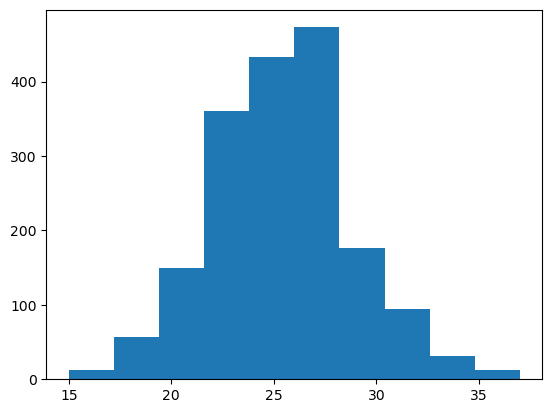

In [90]:
_temp = plt.hist(hp_time_array[indx, 5])

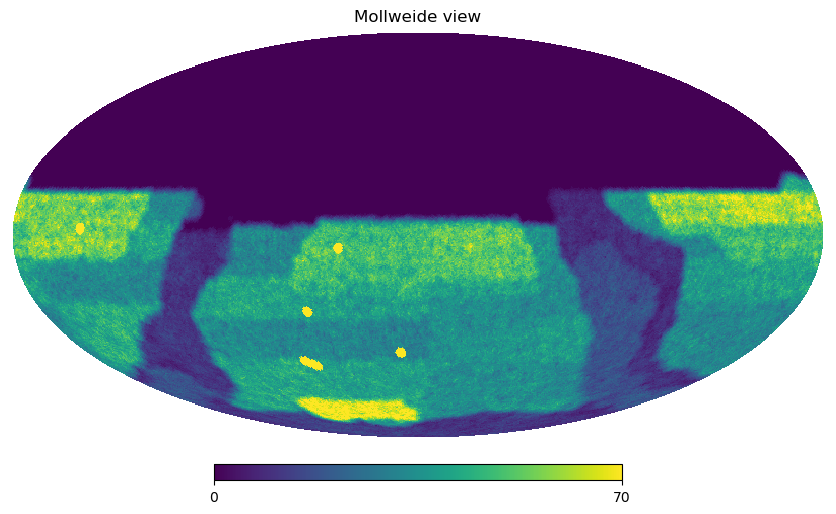

In [67]:
hp.mollview(hp_time_array[:,8], max=70)